# A bola passou pelo Gui? Rede de passes do Golden State Warriors no jogo do recorde de Gui Santos

**Disciplina:** Algoritmos e Estrutura de Dados II (Grafos) · UFRN/DCA · Prof. Ivanovitch Silva · Projeto da Unidade 1

**Pergunta:** *No jogo do recorde de pontos do Gui Santos, a bola passou a fluir por ele (o time jogou para ele) ou ele pontuou fora da estrutura de passes do time?*

**Quem se beneficia:** comissão técnica e scouting, que querem saber se a atuação é **repetível** (efeito estrutural: o time o procura) ou uma **noite fora da curva** (efeito individual: ele criou sozinho).

**Por que só faz sentido em rede:** o box score diz *quantos* pontos ele fez, mas não diz se a bola chegava até ele nem por quem ela passava. Isso é estrutura: centralidade, posição no núcleo, dependência do time em relação a ele.

Cada célula de análise está marcada com `# Conceito: X — Semana N`.

**Como rodar:** com `BAIXAR_DADOS = False` (padrão) o notebook usa só os CSVs de `data/processed/`, que estão no repositório. Com `True`, refaz a coleta na API da NBA (stats.nba.com).

In [1]:
# Configuração geral
BAIXAR_DADOS = False   # True = refaz a coleta na API da NBA (demora alguns minutos)

import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt

from src import rede as r

PROC = Path("data/processed")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

# fontes grandes (legíveis no vídeo) e cores do Warriors
plt.rcParams.update({"font.size": 14, "axes.titlesize": 17, "axes.labelsize": 15,
                     "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
                     "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})
AZUL, OURO, CINZA = "#1D428A", "#FFC72C", "#9aa0a6"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
print("networkx", nx.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

networkx 3.7 | pandas 3.0.6 | matplotlib 3.11.2


In [2]:
# Coleta (só roda com BAIXAR_DADOS = True). Detalhes em src/coleta.py.
if BAIXAR_DADOS:
    from src import coleta
    coleta.coletar_tudo(distribuicao=True)
else:
    print("Usando os CSVs já salvos em data/processed/")

Usando os CSVs já salvos em data/processed/


## Dados: fonte, obtenção e limpeza

**Fonte:** stats.nba.com, a base oficial da NBA, que inclui o rastreamento óptico de jogadores (Second Spectrum), acessada pela biblioteca `nba_api`. Endpoints usados (`src/coleta.py`):

| Etapa | Endpoint | Para quê |
|---|---|---|
| achar o jogador | `players.find_players_by_full_name` | PLAYER_ID do Gui Santos (1630611) |
| achar o jogo | `playercareerstats` + `playergamelog` | log da carreira inteira; jogo com mais pontos |
| nós | `boxscoretraditionalv3`, `commonteamroster` | quem entrou em quadra, minutos, pontos, posição |
| arestas (jogo) | `playerdashptpass` com `DateFrom = DateTo =` data do jogo | passes A → B no jogo |
| arestas (referência) | `playerdashptpass` sem filtro de data | passes A → B na temporada 2025-26 |
| atributos da temporada | `leaguedashplayerstats` | jogos, minutos, pontos, FGA na temporada |
| distribuição (melhoria) | `playerdashptpass` + `teamdashptpass` em cada data | passes do Gui em cada um dos jogos dele |

**Obtenção:** headers de navegador, `timeout=60`, retry com backoff exponencial e pausa de 0,6 s entre requests. Todo JSON bruto fica em `data/raw/` e as tabelas limpas em `data/processed/`. Observação técnica: o stats.nba.com passou a recusar silenciosamente a impressão digital TLS da biblioteca `requests`, por isso trocamos a sessão HTTP da `nba_api` por uma do `curl_cffi`, que imita o Chrome. Os endpoints e parâmetros continuam sendo os da `nba_api`.

In [3]:
# Conceito: dados reais e atributos dos nós — Semana 2
jogo = pd.read_csv(PROC / "jogo_recorde.csv", dtype={"game_id": str}).iloc[0]
placar = pd.read_csv(PROC / "placar.csv").iloc[0]
jj_todos = pd.read_csv(PROC / "jogadores_jogo.csv")
jt = pd.read_csv(PROC / "jogadores_temporada.csv")
aj = pd.read_csv(PROC / "arestas_jogo.csv")
at = pd.read_csv(PROC / "arestas_temporada.csv")
at_fora = pd.read_csv(PROC / "arestas_temporada_fora_da_rede.csv")
rec_j = pd.read_csv(PROC / "recebidos_jogo.csv")
rec_t = pd.read_csv(PROC / "recebidos_temporada.csv")
GUI = int(jogo["player_id"])

print(f"Jogo do recorde: {jogo['data']}  {jogo['confronto']}  ({jogo['resultado']})  "
      f"GSW {placar['pontos']} x {placar['pontos_adversario']} {placar['adversario']}")
print(f"Gui Santos: {jogo['pontos']} pontos em {jogo['minutos']} minutos · GAME_ID {jogo['game_id']}")
jj_todos[["nome", "posicao", "titular", "minutos", "pontos", "assistencias", "fga", "comentario"]]

Jogo do recorde: 03/25/2026  GSW vs. BKN  (W)  GSW 109 x 106 BKN
Gui Santos: 31 pontos em 35 minutos · GAME_ID 0022501060


,nome,posicao,titular,minutos,pontos,assistencias,fga,comentario
0,Gui Santos,F,True,34.90,31,1,16,NaN
1,Draymond Green,F,True,33.60,7,3,4,NaN
2,Kristaps Porziņģis,F-C,True,27.05,17,2,9,NaN
3,De'Anthony Melton,G,True,27.53,14,3,12,NaN
4,Brandin Podziemski,G,True,35.12,22,5,11,NaN
5,Gary Payton II,G,False,24.15,10,2,5,NaN
6,LJ Cryer,G,False,15.37,0,2,4,NaN
7,Omer Yurtseven,NaN,False,7.32,1,0,1,NaN
8,Pat Spencer,G,False,15.23,4,3,5,NaN
9,Will Richard,G,False,19.73,3,0,1,NaN


In [4]:
# Limpeza e checagens
jj = jj_todos[jj_todos["jogou"]].copy()
jj["posicao"] = jj["posicao"].fillna("C")   # Yurtseven (pivô) veio sem posição no elenco
print("Fora da rede do jogo (não entraram em quadra):",
      ", ".join(jj_todos.loc[~jj_todos["jogou"], "nome"] + " (" +
                jj_todos.loc[~jj_todos["jogou"], "comentario"] + ")"))

# 1) passes feitos (A->B, lado de A) x recebidos (B<-A, lado de B) têm que bater
cheque = pd.read_csv(PROC / "checagem_feito_x_recebido.csv")
dif = (cheque["passes"] - cheque["passes_recebido"]).abs().max()
print(f"Checagem feito x recebido: {len(cheque)} pares, maior diferença = {dif:.0f} passe(s)")

# 2) no jogo, todo passe foi para alguém que entrou em quadra (nenhum descarte)
print(f"Arestas do jogo: {len(aj)} · passes para quem não estava em quadra: 0")

# 3) na temporada, parte dos passes foi para jogadores que NÃO entraram neste jogo
fora = at_fora.groupby("destino_nome_api")["passes"].sum().sort_values(ascending=False)
perc_fora = 100 * fora.sum() / (fora.sum() + at["passes"].sum())
print(f"Temporada: {perc_fora:.1f}% dos passes destes 10 jogadores foram para quem ficou fora "
      f"da rede (descartados para manter o mesmo conjunto de nós). Principais destinos:")
print(fora.head(6).to_string())

Fora da rede do jogo (não entraram em quadra): Moses Moody (DND - Injury/Illness), Quinten Post (DND - Injury/Illness)
Checagem feito x recebido: 68 pares, maior diferença = 0 passe(s)
Arestas do jogo: 68 · passes para quem não estava em quadra: 0
Temporada: 40.2% dos passes destes 10 jogadores foram para quem ficou fora da rede (descartados para manter o mesmo conjunto de nós). Principais destinos:
destino_nome_api
Curry, Stephen       1555.0
Butler III, Jimmy    1050.0
Horford, Al           922.0
Moody, Moses          897.0
Post, Quinten         868.0
Hield, Buddy          561.0


**Decisões de limpeza (documentadas):**
- **Nós = os 10 jogadores do GSW que entraram em quadra** (minutos > 0). Moses Moody e Quinten Post ficaram fora por lesão (DND). Stephen Curry e Jimmy Butler nem aparecem na súmula: os dois estavam fora desse jogo, um contexto que pesa muito na interpretação.
- **IDs, não nomes:** as arestas usam `PLAYER_ID`, porque a API escreve os nomes como "Sobrenome, Nome" e com acentos (Porziņģis).
- **Consistência:** os passes de A para B vistos pelo lado de A (`PassesMade`) e pelo lado de B (`PassesReceived`) batem 100%.
- **Rede da temporada com o mesmo conjunto de nós:** passes para jogadores que não estavam neste jogo (Curry, Butler, Horford, Moody...) foram descartados da rede de referência e contabilizados acima. Isso compara estrutura com estrutura, mas a rede da temporada fica "sem as estrelas".
- **Normalização da temporada:** o total de passes A → B na temporada é dividido por `min(jogos de A, jogos de B)`, uma aproximação dos jogos em que o par poderia jogar junto. Sem isso, Porziņģis (15 jogos pelo GSW) e Yurtseven (9) pareceriam periféricos só por terem jogado pouco. Assim, o peso fica em **passes por jogo**, na mesma escala da rede do jogo.
- **Poucos minutos:** Yurtseven jogou 7 minutos. Ele fica na rede (ele estava em quadra), mas lembramos que as medidas dele são instáveis.

## Modelagem

| Elemento | Escolha | Justificativa |
|---|---|---|
| **Nó** | jogador do GSW que entrou em quadra | atributos: minutos, pontos, posição |
| **Aresta** | A → B se A passou para B | passar e receber são papéis diferentes, por isso a rede é **dirigida** |
| **Peso** | número de passes (jogo) ou passes por jogo (temporada) | versão alternativa: assistências |
| **Distância** | `1 / passes` | muitos passes = conexão "curta"; usada em caminhos, closeness e betweenness |
| **Versão não dirigida** | peso(A,B) = A→B + B→A | usada em clustering e k-core, que são definidos para grafos não dirigidos |

**O que fica de fora e por quê:**
- **Adversários (Brooklyn):** a pergunta é sobre a estrutura interna do ataque do GSW, não sobre a interação entre os times.
- **Ordem e momento dos passes:** o rastreamento é **agregado** por par, não sequencial. Não dá para reconstruir posses nem cadeias de passes.
- **Passes não registrados** pelo rastreamento (bolas de transição muito rápidas, tapinhas).
- **Rebotes, roubos e jogadas individuais:** não são passes. É justamente o que a pergunta tenta separar: pontos que vieram da rede contra pontos que vieram de fora dela.

In [5]:
# Conceito: grafo dirigido ponderado com atributos nos nós (DiGraph) — Semana 2
Gj = r.montar_rede(aj, jj)                                   # rede do jogo do recorde
jt_attr = jt.merge(jj[["player_id", "posicao"]], on="player_id")
jt_attr["pontos"] = jt_attr["pontos"] / jt_attr["jogos"]     # pontos POR JOGO (tamanho do nó)
Gt = r.montar_rede(r.normalizar_temporada(at, jt), jt_attr)  # rede da temporada (passes/jogo)
Uj, Ut = r.nao_dirigida(Gj), r.nao_dirigida(Gt)

for nome, G in [("Jogo do recorde", Gj), ("Temporada (por jogo)", Gt)]:
    print(f"{nome:22s} dirigido={G.is_directed()}  nós={G.number_of_nodes()}  "
          f"arestas={G.number_of_edges()}  exemplo de aresta: "
          f"{next(iter(G.edges(data=True)))[2]}")

Jogo do recorde        dirigido=True  nós=10  arestas=68  exemplo de aresta: {'peso': 6.0, 'distancia': 0.16666666666666666, 'passes': 6.0, 'assistencias': 0.0}
Temporada (por jogo)   dirigido=True  nós=10  arestas=88  exemplo de aresta: {'peso': 3.611111111111111, 'distancia': 0.27692307692307694, 'passes': 3.611111111111111, 'assistencias': 0.2222222222222222}


## 1. Descrição da rede

In [6]:
# Conceito: número de nós e arestas, densidade, reciprocidade — Semana 2
resumo = pd.DataFrame({"Jogo do recorde": r.resumo(Gj), "Temporada (por jogo)": r.resumo(Gt)})
resumo.loc[["nos", "arestas", "densidade", "reciprocidade", "passes_totais"]]

,Jogo do recorde,Temporada (por jogo)
nos,10.000,10.000
arestas,68.000,88.000
densidade,0.756,0.978
reciprocidade,0.912,1.000
passes_totais,317.000,255.748


A rede do jogo tem densidade de aproximadamente 0,76: dos 90 pares ordenados possíveis, cerca de três quartos tiveram ao menos um passe. Na temporada, quase todos os pares trocaram passes em algum momento (densidade perto de 1). **Por isso o grau sem peso discrimina pouco os jogadores, e as medidas ponderadas (força e centralidades com peso) são as que importam aqui.**

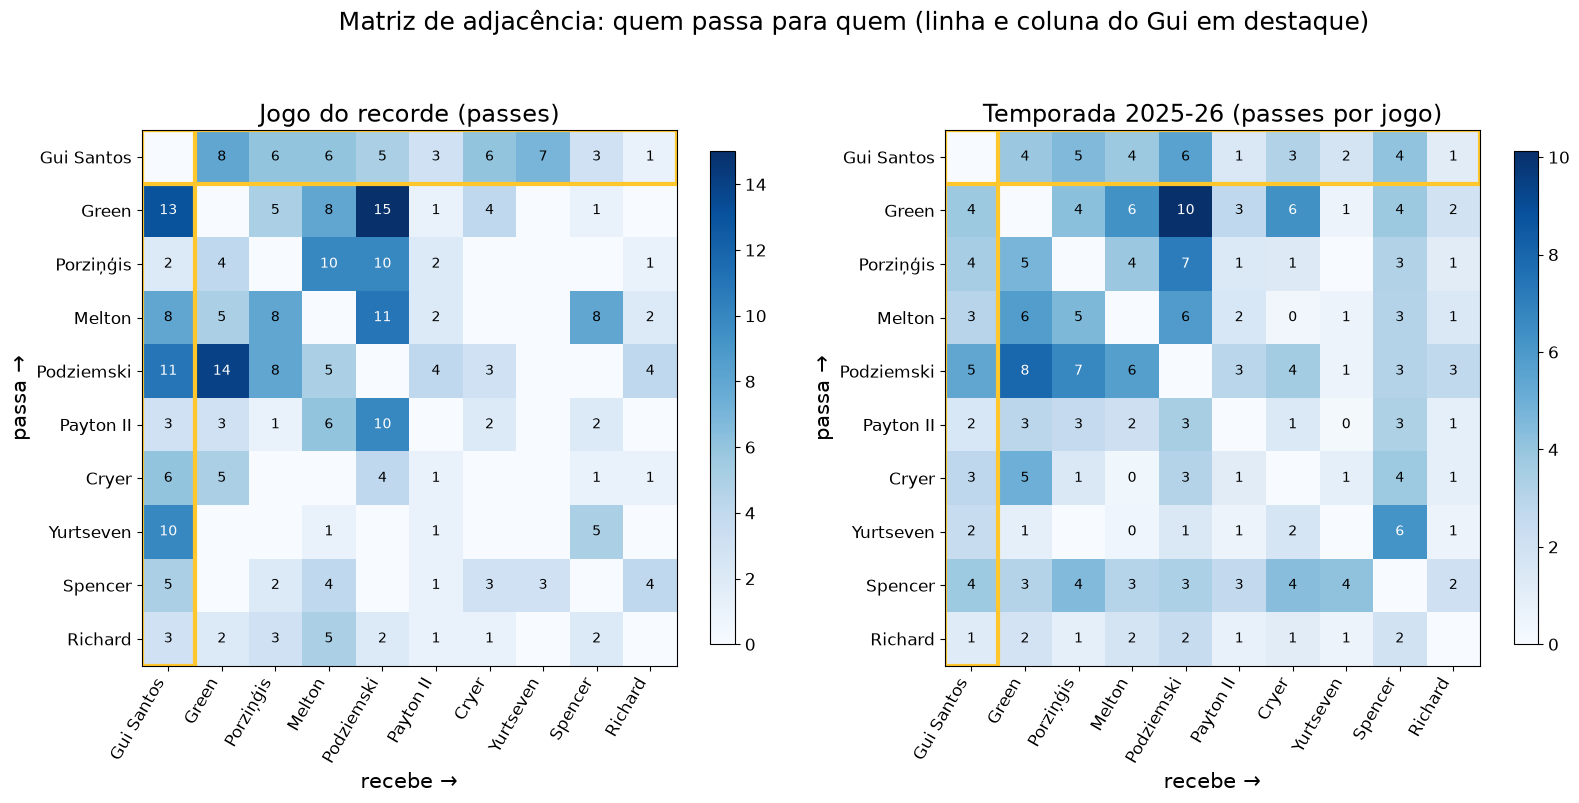

In [7]:
# Conceito: matriz de adjacência (ponderada) como heatmap — Semana 2
ordem = list(Gj.nodes)
fig, axes = plt.subplots(1, 2, figsize=(19, 8))
for ax, G, titulo in [(axes[0], Gj, "Jogo do recorde (passes)"),
                      (axes[1], Gt, "Temporada 2025-26 (passes por jogo)")]:
    M = r.matriz_adjacencia(G, ordem)
    im = ax.imshow(M.values, cmap="Blues")
    ax.set_xticks(range(len(M)), M.columns, rotation=60, ha="right")
    ax.set_yticks(range(len(M)), M.index)
    for i in range(len(M)):
        for j in range(len(M)):
            v = M.values[i, j]
            if v > 0:
                ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=10,
                        color="white" if v > M.values.max() * 0.6 else "black")
    gi = M.index.get_loc("Gui Santos")
    ax.add_patch(plt.Rectangle((-0.5, gi - 0.5), len(M), 1, fill=False, ec=OURO, lw=3))
    ax.add_patch(plt.Rectangle((gi - 0.5, -0.5), 1, len(M), fill=False, ec=OURO, lw=3))
    ax.set_title(titulo); ax.set_xlabel("recebe →"); ax.set_ylabel("passa →")
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle("Matriz de adjacência: quem passa para quem (linha e coluna do Gui em destaque)", fontsize=18)
plt.savefig(FIG / "02_heatmap_adjacencia.png"); plt.show()

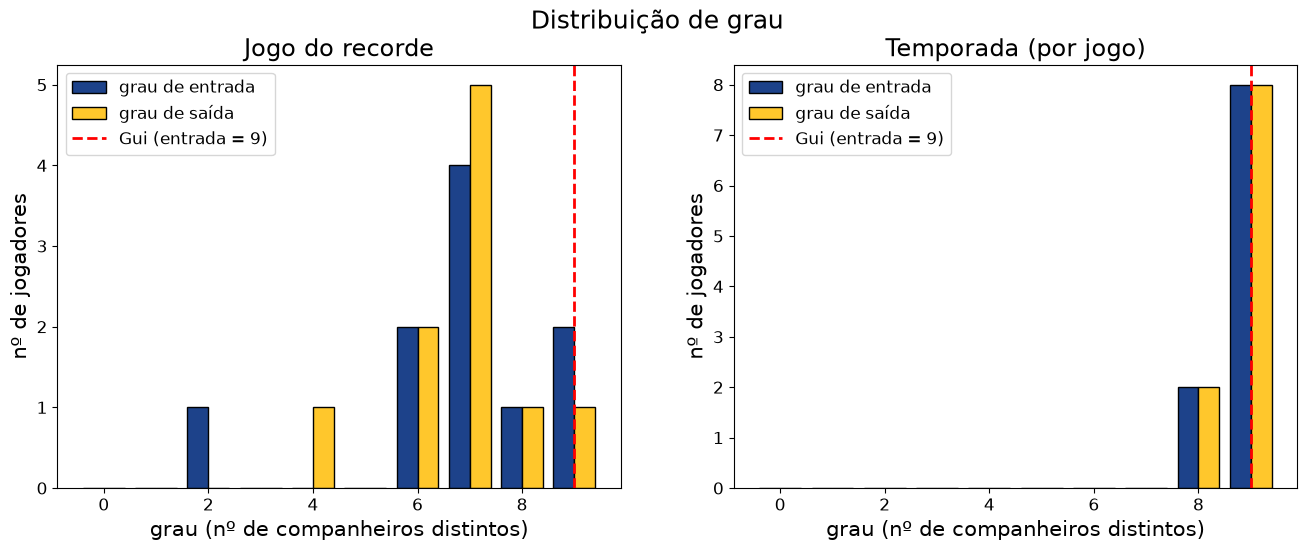

In [8]:
# Conceito: grau e distribuição de grau (entrada e saída, sem peso e com peso) — Semana 2
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, G, titulo in [(axes[0], Gj, "Jogo do recorde"), (axes[1], Gt, "Temporada (por jogo)")]:
    k_in = [d for _, d in G.in_degree()]; k_out = [d for _, d in G.out_degree()]
    bins = np.arange(0, G.number_of_nodes() + 1) - 0.5
    ax.hist([k_in, k_out], bins=bins, label=["grau de entrada", "grau de saída"],
            color=[AZUL, OURO], edgecolor="black")
    gi = G.in_degree(GUI)
    ax.axvline(gi, color="red", ls="--", lw=2, label=f"Gui (entrada = {gi})")
    ax.set_title(titulo); ax.set_xlabel("grau (nº de companheiros distintos)"); ax.set_ylabel("nº de jogadores")
    ax.legend()
fig.suptitle("Distribuição de grau", fontsize=18)
plt.savefig(FIG / "05_distribuicao_grau.png"); plt.show()

## 2. Entrada e saída: quem recebe e quem distribui

In [9]:
# Conceito: grau de entrada e de saída ponderados (força) + núcleo e periferia — Semana 3
mj = r.medidas_nos(Gj)
mt = r.medidas_nos(Gt)
min_jogo = mj["minutos"].to_dict()
min_temp = (jt.set_index("nome")["minutos"] / jt.set_index("nome")["jogos"])  # minutos por jogo
min_temp.index = min_temp.index.map(r.nome_curto)
mj = r.forca_por_36(mj, min_jogo)
mt = r.forca_por_36(mt, min_temp.to_dict())
mj["papel"] = r.nucleo_periferia(mj)
mt["papel"] = r.nucleo_periferia(mt)

cols = ["minutos", "pontos", "forca_entrada", "forca_saida", "recebidos_36", "feitos_36",
        "parcela_recebida", "papel"]
print("JOGO DO RECORDE (ordenado por passes recebidos)")
display(mj[cols].sort_values("forca_entrada", ascending=False))
print("TEMPORADA, por jogo (ordenado por passes recebidos)")
display(mt[cols].sort_values("forca_entrada", ascending=False))

JOGO DO RECORDE (ordenado por passes recebidos)


,minutos,pontos,forca_entrada,forca_saida,recebidos_36,feitos_36,parcela_recebida,papel
jogador,,,,,,,,
Gui Santos,34.90,31.0,61.0,45.0,62.923,46.418,0.192,núcleo
Podziemski,35.12,22.0,57.0,49.0,58.428,50.228,0.180,núcleo
Melton,27.53,14.0,45.0,44.0,58.845,57.537,0.142,núcleo
Green,33.60,7.0,41.0,47.0,43.929,50.357,0.129,núcleo
Porziņģis,27.05,17.0,33.0,29.0,43.919,38.595,0.104,núcleo
Spencer,15.23,4.0,22.0,22.0,52.003,52.003,0.069,periferia
Cryer,15.37,0.0,19.0,18.0,44.502,42.160,0.060,periferia
Payton II,24.15,10.0,16.0,27.0,23.851,40.248,0.050,periferia
Richard,19.73,3.0,13.0,19.0,23.720,34.668,0.041,periferia


TEMPORADA, por jogo (ordenado por passes recebidos)


,minutos,pontos,forca_entrada,forca_saida,recebidos_36,feitos_36,parcela_recebida,papel
jogador,,,,,,,,
Podziemski,2332.673,13.817,42.457,38.673,53.729,48.940,0.166,núcleo
Green,1868.888,8.382,36.018,39.774,47.179,52.098,0.141,núcleo
Spencer,1228.927,7.212,32.417,30.912,62.675,59.765,0.127,núcleo
Porziņģis,355.793,16.133,29.533,26.200,44.824,39.765,0.115,núcleo
Gui Santos,1395.363,9.191,27.463,29.394,48.181,51.568,0.107,núcleo
Melton,1125.257,12.286,27.455,26.244,43.040,41.141,0.107,periferia
Cryer,292.147,8.222,23.211,19.467,51.484,43.178,0.091,periferia
Payton II,1142.280,7.493,15.123,18.335,34.793,42.183,0.059,periferia
Richard,1376.805,6.391,12.848,12.528,23.180,22.603,0.050,periferia


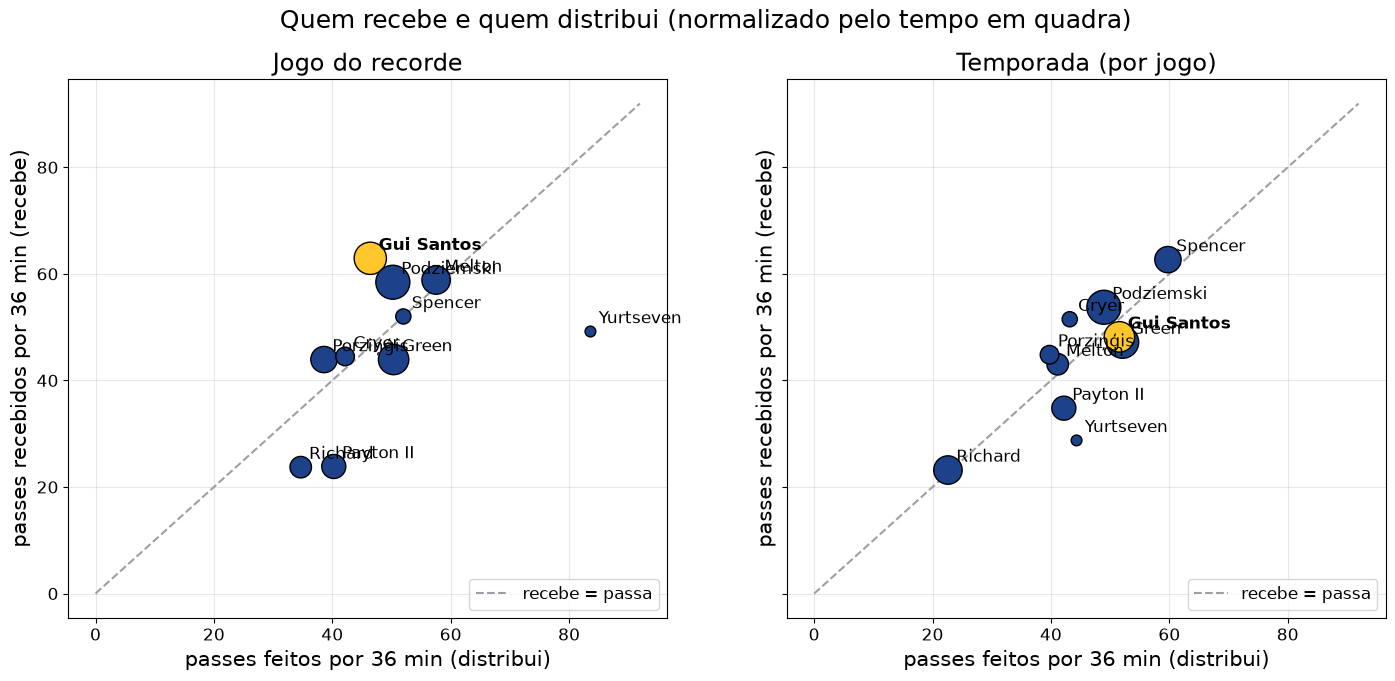

In [10]:
# Figura: recebidos x feitos por 36 minutos (controle de minutos em quadra)
fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharex=True, sharey=True)
for ax, m, titulo in [(axes[0], mj, "Jogo do recorde"), (axes[1], mt, "Temporada (por jogo)")]:
    cores = [OURO if j == "Gui Santos" else AZUL for j in m.index]
    ax.scatter(m["feitos_36"], m["recebidos_36"], s=m["minutos"].rank() * 60, c=cores,
               edgecolor="black", zorder=3)
    for j, row in m.iterrows():
        ax.annotate(j, (row["feitos_36"], row["recebidos_36"]), xytext=(6, 6),
                    textcoords="offset points", fontsize=12,
                    fontweight="bold" if j == "Gui Santos" else "normal")
    lim = max(mj[["feitos_36", "recebidos_36"]].max().max(), mt[["feitos_36", "recebidos_36"]].max().max()) * 1.1
    ax.plot([0, lim], [0, lim], color=CINZA, ls="--", label="recebe = passa")
    ax.set_title(titulo); ax.set_xlabel("passes feitos por 36 min (distribui)")
    ax.set_ylabel("passes recebidos por 36 min (recebe)"); ax.legend(loc="lower right")
    ax.grid(alpha=0.3)
fig.suptitle("Quem recebe e quem distribui (normalizado pelo tempo em quadra)", fontsize=18)
plt.savefig(FIG / "06_entrada_saida_por36.png"); plt.show()

**Atenção ao confundidor "minutos":** quem fica mais tempo em quadra naturalmente passa e recebe mais. O Gui jogou 34,9 minutos, o segundo maior tempo do time nesse jogo. Por isso olhamos sempre a força **por 36 minutos** e a **parcela** dos passes do time: elas tiram o efeito do tempo em quadra.

In [11]:
# Conceito: BFS, DFS e amostragem snowball a partir do Gui — Semana 3
# No grafo completo todo mundo está a 1 ou 2 passos (rede densa). Para a busca ficar
# informativa, usamos o esqueleto com ligações "fortes" (>= 5 passes no jogo).
H = r.esqueleto(Gj, 5)
rot = nx.get_node_attributes(Gj, "rotulo")
camadas = nx.bfs_layers(H, [GUI])
print("BFS a partir do Gui (arestas com >= 5 passes), camada = nº de passes até chegar:")
for i, camada in enumerate(camadas):
    print(f"  camada {i}: {[rot[v] for v in camada]}")
print("\nOrdem da DFS (pré-ordem) a partir do Gui:", [rot[v] for v in nx.dfs_preorder_nodes(H, GUI)])

# snowball: onda 0 = Gui; cada onda inclui quem RECEBE passe forte dos já amostrados
amostra, onda = {GUI}, {GUI}
for k in range(1, 3):
    onda = {v for u in onda for v in H.successors(u)} - amostra
    amostra |= onda
    print(f"Snowball, onda {k}: +{[rot[v] for v in onda]}  (total {len(amostra)} de {H.number_of_nodes()})")

# o caminho inverso: quem alimenta o Gui com passes fortes
print("\nAlimentam o Gui com >= 5 passes:", [f"{rot[u]} ({Gj[u][GUI]['peso']:.0f})" for u in H.predecessors(GUI)])

BFS a partir do Gui (arestas com >= 5 passes), camada = nº de passes até chegar:
  camada 0: ['Gui Santos']
  camada 1: ['Cryer', 'Podziemski', 'Yurtseven', 'Melton', 'Porziņģis', 'Green']
  camada 2: ['Spencer']

Ordem da DFS (pré-ordem) a partir do Gui: ['Gui Santos', 'Cryer', 'Green', 'Podziemski', 'Melton', 'Spencer', 'Porziņģis', 'Yurtseven']
Snowball, onda 1: +['Yurtseven', 'Porziņģis', 'Podziemski', 'Green', 'Melton', 'Cryer']  (total 7 de 10)
Snowball, onda 2: +['Spencer']  (total 8 de 10)

Alimentam o Gui com >= 5 passes: ['Green (13)', 'Melton (8)', 'Podziemski (11)', 'Cryer (6)', 'Yurtseven (10)', 'Spencer (5)']


## 3. Componentes e caminhos

In [12]:
# Conceito: componentes (WCC, SCC), distâncias, diâmetro e eficiência global — Semana 4
linhas = ["n_wcc", "n_scc", "maior_scc", "diametro_saltos", "dist_media_saltos",
          "eficiencia_global_nao_ponderada", "eficiencia_global_ponderada"]
display(resumo.loc[linhas])

# distância ponderada (1/passes) média ATÉ cada jogador: quanto menor, mais fácil a bola chegar
dist = dict(nx.all_pairs_dijkstra_path_length(Gj, weight="distancia"))
chegada = {rot[v]: np.mean([dist[u][v] for u in Gj if u != v]) for v in Gj}
print("Distância ponderada média até o jogador (jogo):")
print(pd.Series(chegada).sort_values().round(3).to_string())

,Jogo do recorde,Temporada (por jogo)
n_wcc,1.000,1.000
n_scc,1.000,1.000
maior_scc,10.000,10.000
diametro_saltos,2.000,2.000
dist_media_saltos,1.244,1.022
eficiencia_global_nao_ponderada,0.911,0.989
eficiencia_global_ponderada,4.828,3.230


Distância ponderada média até o jogador (jogo):
Gui Santos    0.163
Podziemski    0.191
Melton        0.200
Green         0.202
Porziņģis     0.236
Spencer       0.276
Yurtseven     0.294
Cryer         0.307
Richard       0.361
Payton II     0.400


As duas redes são uma única componente fortemente conexa: a bola consegue ir de qualquer jogador a qualquer outro. O diâmetro é 2 saltos. Numa rede tão pequena e densa, componentes e diâmetro não discriminam ninguém. O que muda é a **distância ponderada**: a bola chega "mais perto" de quem recebe muitos passes de muitos companheiros.

Observação sobre a eficiência ponderada: ela usa distância = 1/passes, então seu valor absoluto depende da escala do peso (passes num jogo contra passes por jogo na temporada). Ela serve para comparar a **mesma** rede antes e depois de uma remoção (seção 6), não o jogo com a temporada.

## 4. Centralidades

In [13]:
# Conceito: centralidades de grau, closeness, betweenness, eigenvector e clustering — Semana 4
# - closeness_entrada: distância (1/passes) dos OUTROS até o jogador -> facilidade de a bola chegar nele
# - betweenness: com distância = 1/passes (muitos passes = caminho curto)
# - eigenvector_entrada: em DiGraph o NetworkX usa o autovetor à esquerda, ou seja, as arestas de
#   ENTRADA: prestígio de quem recebe passes de quem também recebe muitos passes
# - clustering: na versão NÃO dirigida e ponderada (pesos normalizados em [0,1])
cent = ["centralidade_grau", "closeness_entrada", "betweenness", "eigenvector_entrada",
        "pagerank", "clustering"]
print("JOGO DO RECORDE"); display(mj[cent].sort_values("betweenness", ascending=False))
print("TEMPORADA (por jogo)"); display(mt[cent].sort_values("betweenness", ascending=False))

JOGO DO RECORDE


,centralidade_grau,closeness_entrada,betweenness,eigenvector_entrada,pagerank,clustering
jogador,,,,,,
Gui Santos,1.000,6.138,0.326,0.480,0.172,0.236
Podziemski,0.778,5.224,0.312,0.491,0.162,0.354
Melton,0.889,5.010,0.208,0.376,0.134,0.262
Green,0.889,4.962,0.097,0.411,0.132,0.255
Spencer,0.889,3.629,0.014,0.161,0.071,0.137
Porziņģis,0.778,4.235,0.000,0.336,0.104,0.262
Payton II,1.000,2.501,0.000,0.153,0.060,0.146
Cryer,0.667,3.253,0.000,0.182,0.067,0.196
Yurtseven,0.444,3.406,0.000,0.102,0.046,0.176


TEMPORADA (por jogo)


,centralidade_grau,closeness_entrada,betweenness,eigenvector_entrada,pagerank,clustering
jogador,,,,,,
Podziemski,1.000,3.826,0.222,0.477,0.156,0.366
Spencer,1.000,3.315,0.208,0.319,0.121,0.319
Green,1.000,3.376,0.111,0.418,0.139,0.350
Melton,1.000,2.939,0.000,0.340,0.105,0.277
Gui Santos,1.000,2.834,0.000,0.319,0.107,0.305
Payton II,1.000,2.005,0.000,0.186,0.066,0.222
Porziņģis,0.889,3.189,0.000,0.364,0.112,0.345
Cryer,1.000,2.750,0.000,0.276,0.089,0.241
Yurtseven,0.889,1.897,0.000,0.102,0.046,0.170


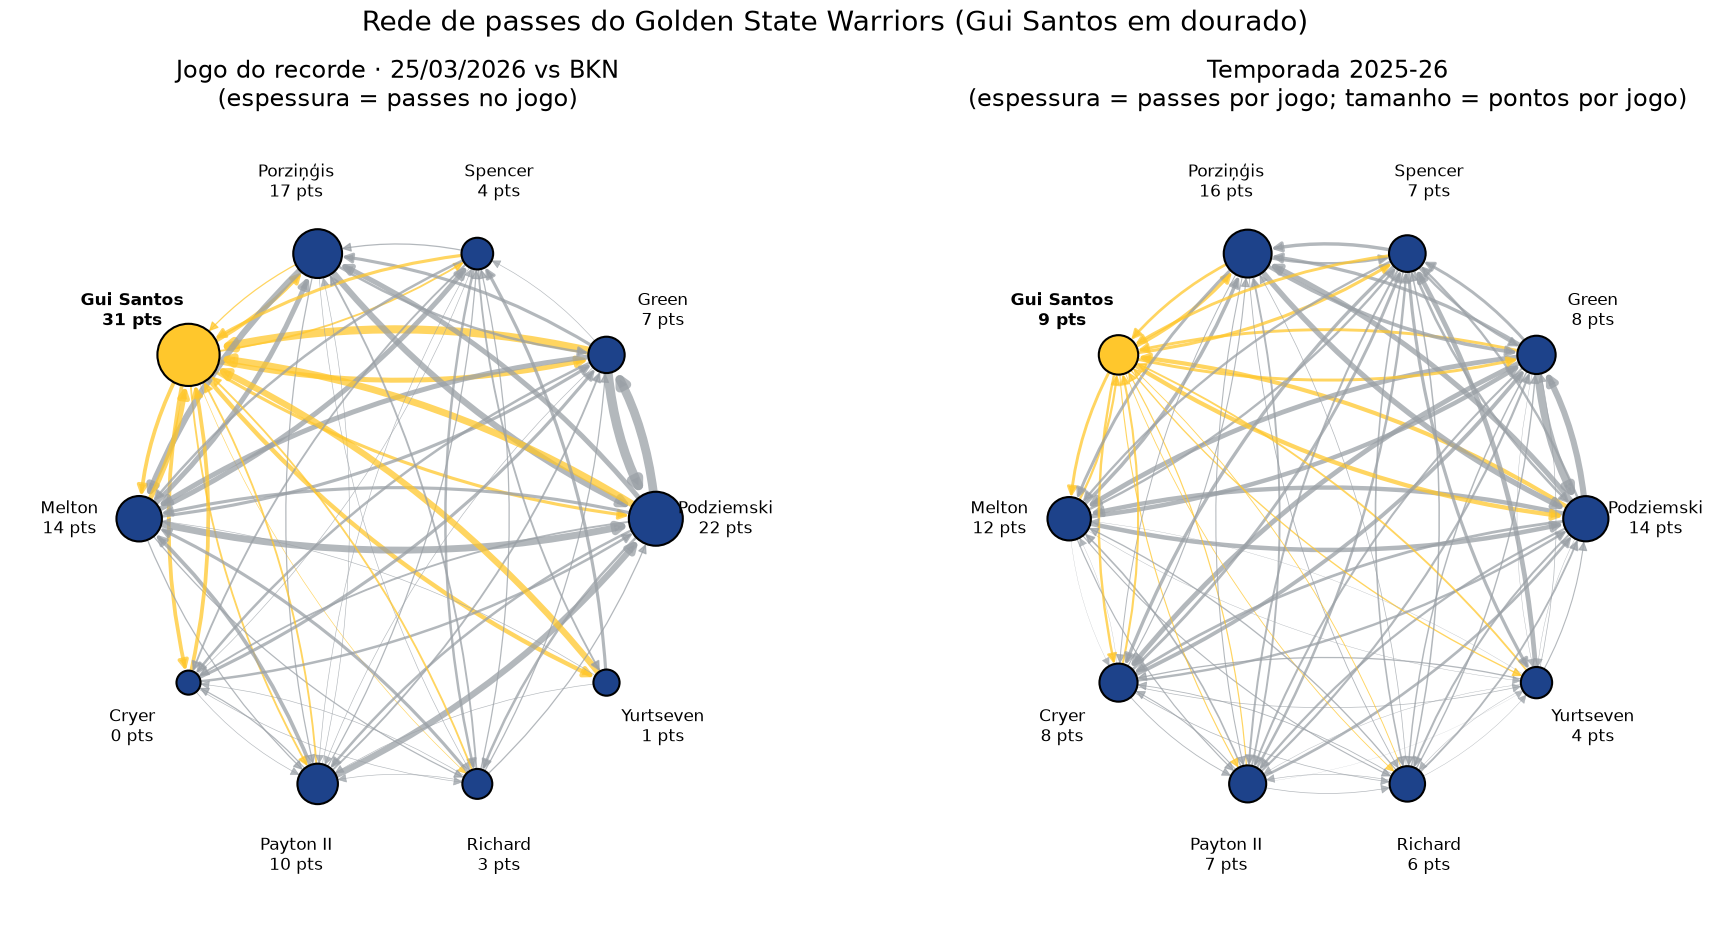

In [14]:
# Conceito: visualização da rede (layout circular, espessura = passes, tamanho = pontos) — Semana 4
def desenhar(G, ax, titulo, pos, escala_aresta, escala_no):
    larg = [d["peso"] * escala_aresta for _, _, d in G.edges(data=True)]
    cor_aresta = [OURO if GUI in (u, v) else CINZA for u, v in G.edges()]
    nx.draw_networkx_edges(G, pos, ax=ax, width=larg, edge_color=cor_aresta, alpha=0.75,
                           arrows=True, arrowsize=14, connectionstyle="arc3,rad=0.12",
                           node_size=[G.nodes[n]["pontos"] * escala_no + 300 for n in G])
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[OURO if n == GUI else AZUL for n in G],
                           node_size=[G.nodes[n]["pontos"] * escala_no + 300 for n in G],
                           edgecolors="black", linewidths=1.5)
    for n, (x, y) in pos.items():
        ax.text(x * 1.27, y * 1.27, f"{G.nodes[n]['rotulo']}\n{G.nodes[n]['pontos']:.0f} pts",
                ha="center", va="center", fontsize=12,
                fontweight="bold" if n == GUI else "normal")
    ax.set_title(titulo); ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.45, 1.45); ax.axis("off")

ordem_pos = mt.sort_values("forca_entrada", ascending=False)["player_id"].tolist()
pos = nx.circular_layout(ordem_pos)   # mesma posição nas duas redes
fig, axes = plt.subplots(1, 2, figsize=(22, 10.5))
desenhar(Gj, axes[0], "Jogo do recorde · 25/03/2026 vs BKN\n(espessura = passes no jogo)", pos, 0.45, 55)
desenhar(Gt, axes[1], "Temporada 2025-26\n(espessura = passes por jogo; tamanho = pontos por jogo)", pos, 0.55, 55)
fig.suptitle("Rede de passes do Golden State Warriors (Gui Santos em dourado)", fontsize=20)
plt.savefig(FIG / "01_rede_jogo_vs_temporada.png"); plt.show()

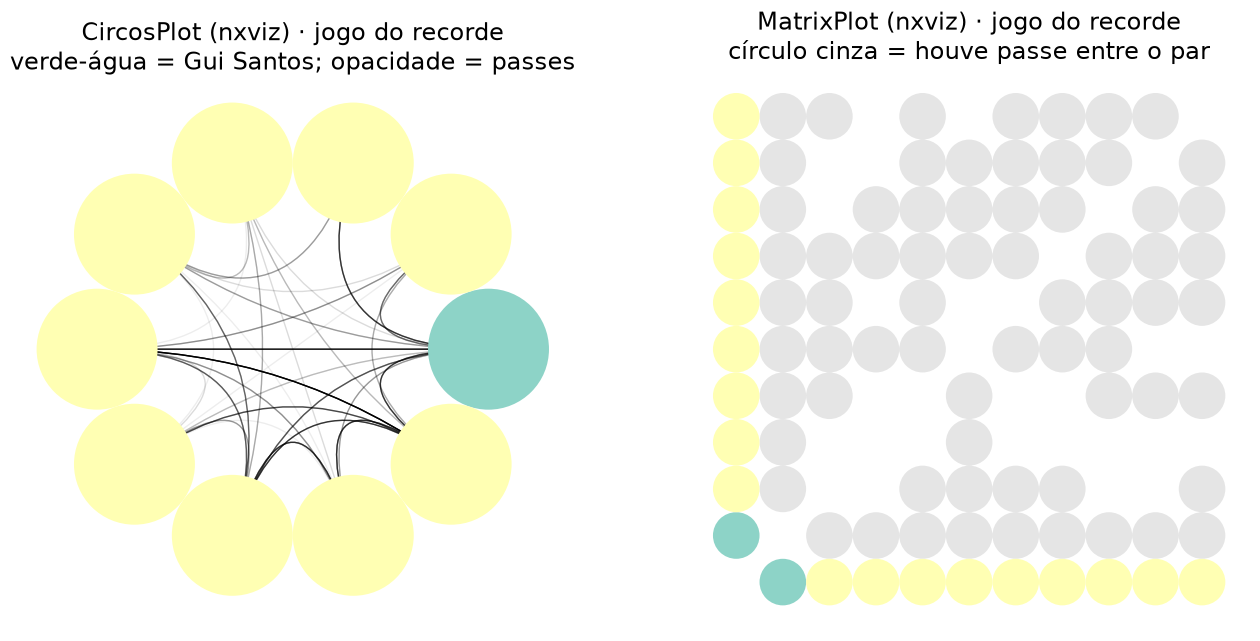

In [15]:
# Conceito: visualização com nxviz (CircosPlot e MatrixPlot) — Semana 4
# O nxviz 0.9 ainda importa matplotlib.cm.get_cmap, removido no matplotlib 3.9+;
# este shim de uma linha restaura a função sem mudar nada no resto.
import matplotlib.cm
if not hasattr(matplotlib.cm, "get_cmap"):
    matplotlib.cm.get_cmap = matplotlib.colormaps.get_cmap
import nxviz as nv

Gv = Gj.copy()
for n in Gv:
    Gv.nodes[n]["grupo"] = "Gui Santos" if n == GUI else "outros"
fig = plt.figure(figsize=(16, 8))
ax1 = fig.add_subplot(1, 2, 1); plt.sca(ax1)
nv.circos(Gv, group_by="grupo", sort_by="pontos", node_color_by="grupo", edge_alpha_by="peso")
ax1.set_title("CircosPlot (nxviz) · jogo do recorde\nverde-água = Gui Santos; opacidade = passes")
ax2 = fig.add_subplot(1, 2, 2); plt.sca(ax2)
nv.matrix(Gv, group_by="grupo", sort_by="pontos", node_color_by="grupo")
ax2.set_title("MatrixPlot (nxviz) · jogo do recorde\ncírculo cinza = houve passe entre o par")
plt.savefig(FIG / "09_nxviz_circos_matrix.png"); plt.show()

## 5. Núcleos: k-core e core number

In [16]:
# Conceito: k-core, core number, degeneracy e onion layers (versão não dirigida) — Semana 5
nucleos = pd.DataFrame({"core_jogo": nx.core_number(Uj), "core_temporada": nx.core_number(Ut)})
nucleos["onion_jogo"] = pd.Series(nx.onion_layers(Uj))
nucleos.index = nucleos.index.map(rot)
print(f"Degeneracy (maior k com k-core não vazio): jogo = {max(nucleos.core_jogo)}, "
      f"temporada = {max(nucleos.core_temporada)}")
display(nucleos.sort_values(["core_jogo", "onion_jogo"], ascending=False))

# Como a rede é densa, o k-core sem peso põe quase todos no mesmo núcleo.
# Para separar núcleo e periferia "de verdade", aplicamos o k-core ao esqueleto
# com limiar de passes (semana 6): só ligações com >= k passes (soma A->B + B->A).
tab = {}
for k in [1, 3, 5, 8]:
    U_k = nx.Graph([(u, v) for u, v, d in Uj.edges(data=True) if d["peso"] >= k])
    U_k.add_nodes_from(Uj)
    cn = nx.core_number(U_k)
    tab[f"limiar ≥{k}"] = {rot[v]: cn[v] for v in Uj}
core_limiar = pd.DataFrame(tab)
core_limiar["max_k_core"] = core_limiar.max(axis=1)
display(core_limiar.sort_values(list(tab)[::-1], ascending=False))

# k-truss: subgrafo em que cada aresta está em pelo menos k-2 triângulos (coesão por triangulação)
for limiar in [1, 5]:
    U_k = nx.Graph([(u, v) for u, v, d in Uj.edges(data=True) if d["peso"] >= limiar])
    k, ultimo = 2, None
    while True:
        T = nx.k_truss(U_k, k + 1)
        if T.number_of_nodes() == 0:
            break
        k, ultimo = k + 1, T
    print(f"limiar ≥{limiar}: maior k-truss = {k}-truss com {sorted(rot[v] for v in ultimo)}")

Degeneracy (maior k com k-core não vazio): jogo = 6, temporada = 8


,core_jogo,core_temporada,onion_jogo
Gui Santos,6,8,4
Green,6,8,4
Porziņģis,6,8,4
Melton,6,8,4
Payton II,6,8,4
Richard,6,8,4
Podziemski,6,8,3
Spencer,6,8,3
Cryer,6,8,2
Yurtseven,4,8,1


,limiar ≥1,limiar ≥3,limiar ≥5,limiar ≥8,max_k_core
Gui Santos,6,5,4,4,6
Green,6,5,4,4,6
Porziņģis,6,5,4,4,6
Melton,6,5,4,4,6
Podziemski,6,5,4,4,6
Payton II,6,5,3,2,6
Cryer,6,5,3,2,6
Spencer,6,5,3,2,6
Yurtseven,4,2,2,2,4
Richard,6,5,3,0,6


limiar ≥1: maior k-truss = 7-truss com ['Green', 'Gui Santos', 'Melton', 'Payton II', 'Podziemski', 'Porziņģis', 'Richard', 'Spencer']
limiar ≥5: maior k-truss = 5-truss com ['Green', 'Gui Santos', 'Melton', 'Podziemski', 'Porziņģis']


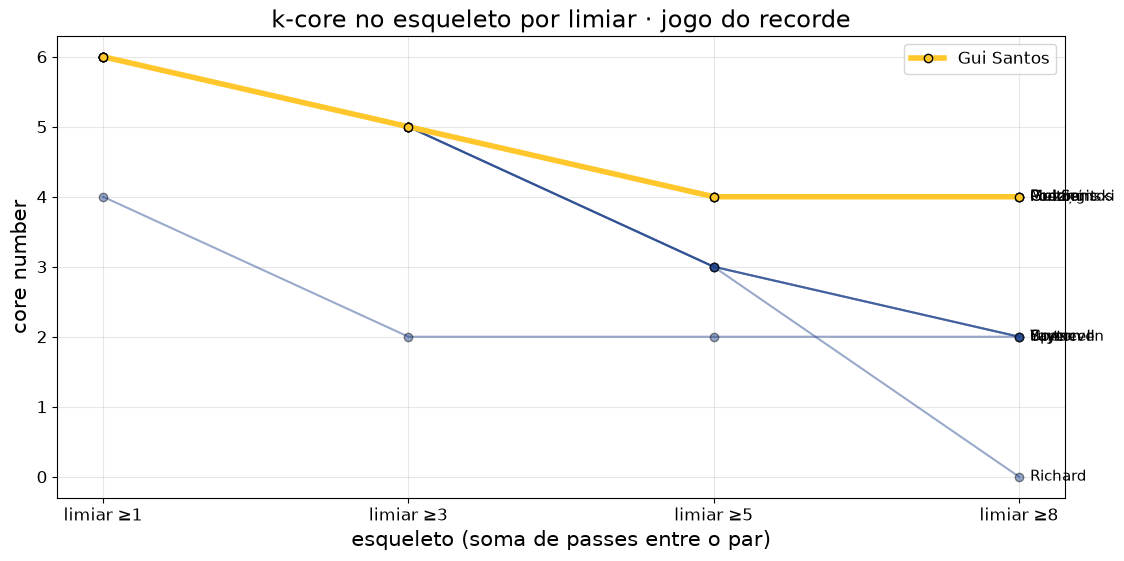

In [17]:
# Figura: core number por limiar (quem continua no núcleo quando só ligações fortes contam)
fig, ax = plt.subplots(figsize=(13, 6))
dados = core_limiar.drop(columns="max_k_core")
ordem_j = dados.sort_values(list(dados.columns)[::-1], ascending=False).index
for j in ordem_j:
    ax.plot(dados.columns, dados.loc[j], marker="o", lw=4 if j == "Gui Santos" else 1.5,
            color=OURO if j == "Gui Santos" else AZUL, alpha=1 if j == "Gui Santos" else 0.45,
            label=j if j == "Gui Santos" else None, zorder=3 if j == "Gui Santos" else 2,
            markeredgecolor="black")
fim = dados.iloc[:, -1]
for j, v in fim.items():
    ax.annotate(j, (len(dados.columns) - 1, v), xytext=(8, 0), textcoords="offset points",
                fontsize=11, va="center")
ax.set_ylabel("core number"); ax.set_xlabel("esqueleto (soma de passes entre o par)")
ax.set_title("k-core no esqueleto por limiar · jogo do recorde"); ax.legend(); ax.grid(alpha=0.3)
plt.savefig(FIG / "07_kcore_por_limiar.png"); plt.show()

## 6. Robustez: e se tirarmos o Gui?

In [18]:
# Conceito: robustez por remoção de nó (eficiência, componentes, centralidade dos outros) — Semana 4
mais_central = mj.drop(index="Gui Santos")["betweenness"].idxmax()
id_mais_central = int(mj.loc[mais_central, "player_id"])
rob = pd.DataFrame([r.robustez(Gj, GUI), r.robustez(Gj, id_mais_central)]).set_index("removido")
outros = r.robustez_media_aleatoria(Gj, excluir=(GUI, id_mais_central))
rob.loc["média dos outros 8"] = outros.drop(columns="removido").mean()
print(f"Jogador mais central depois do Gui (betweenness): {mais_central}")
display(rob[["passes_perdidos_%", "eficiencia_antes", "eficiencia_depois", "queda_eficiencia_%",
             "n_scc_depois", "variacao_media_betweenness_outros"]])

# mesma análise na temporada (comparação)
mais_central_t = mt.drop(index="Gui Santos")["betweenness"].idxmax()
rob_t = pd.DataFrame([r.robustez(Gt, GUI),
                      r.robustez(Gt, int(mt.loc[mais_central_t, "player_id"]))]).set_index("removido")
print("Temporada:")
display(rob_t[["passes_perdidos_%", "queda_eficiencia_%", "n_scc_depois"]])

Jogador mais central depois do Gui (betweenness): Podziemski


,passes_perdidos_%,eficiencia_antes,eficiencia_depois,queda_eficiencia_%,n_scc_depois,variacao_media_betweenness_outros
removido,,,,,,
Gui Santos,33.438,4.828,4.077,15.557,1.0,0.079
Podziemski,33.438,4.828,4.077,15.554,1.0,0.053
média dos outros 8,16.640,4.828,4.915,-1.812,1.0,0.021


Temporada:


,passes_perdidos_%,queda_eficiencia_%,n_scc_depois
removido,,,
Gui Santos,22.232,0.489,1
Podziemski,31.723,12.565,1


Nenhuma remoção desconecta a rede (continua uma SCC única), porque o time é denso demais. A medida que discrimina é a **queda de eficiência ponderada** e a fração de passes que somem junto com o jogador. Se a rede do jogo perde mais eficiência sem o Gui do que sem qualquer outro, ele virou uma peça de que a circulação dependia naquela noite.

## 7. Comparação central da pergunta: jogo do recorde × temporada

In [19]:
# Conceito: comparação de centralidades (rank e valor normalizado) entre duas redes — Semana 4
medidas = {"forca_entrada": "passes recebidos", "recebidos_36": "recebidos por 36 min",
           "parcela_recebida": "parcela dos passes do time", "closeness_entrada": "closeness (entrada)",
           "betweenness": "betweenness", "eigenvector_entrada": "eigenvector (entrada)",
           "pagerank": "PageRank", "forca_saida": "passes feitos"}
rk_j, rk_t = r.ranks(mj, list(medidas)), r.ranks(mt, list(medidas))
comp = pd.DataFrame({
    "medida": list(medidas.values()),
    "rank_jogo": rk_j.loc["Gui Santos"].values,
    "rank_temporada": rk_t.loc["Gui Santos"].values,
    "valor_jogo / máx": (mj.loc["Gui Santos", list(medidas)] / mj[list(medidas)].max()).values,
    "valor_temp / máx": (mt.loc["Gui Santos", list(medidas)] / mt[list(medidas)].max()).values,
}).set_index("medida")
comp["subiu?"] = np.where(comp["rank_jogo"] < comp["rank_temporada"], "sim ↑",
                          np.where(comp["rank_jogo"] == comp["rank_temporada"], "igual", "não ↓"))
comp.to_csv(PROC / "comparacao_gui_jogo_temporada.csv")
comp

,rank_jogo,rank_temporada,valor_jogo / máx,valor_temp / máx,subiu?
medida,,,,,
passes recebidos,1,5,1.000,0.647,sim ↑
recebidos por 36 min,1,4,1.000,0.769,sim ↑
parcela dos passes do time,1,5,1.000,0.647,sim ↑
closeness (entrada),1,6,1.000,0.741,sim ↑
betweenness,1,10,1.000,0.000,sim ↑
eigenvector (entrada),2,5,0.978,0.669,sim ↑
PageRank,1,5,1.000,0.690,sim ↑
passes feitos,3,4,0.918,0.739,sim ↑


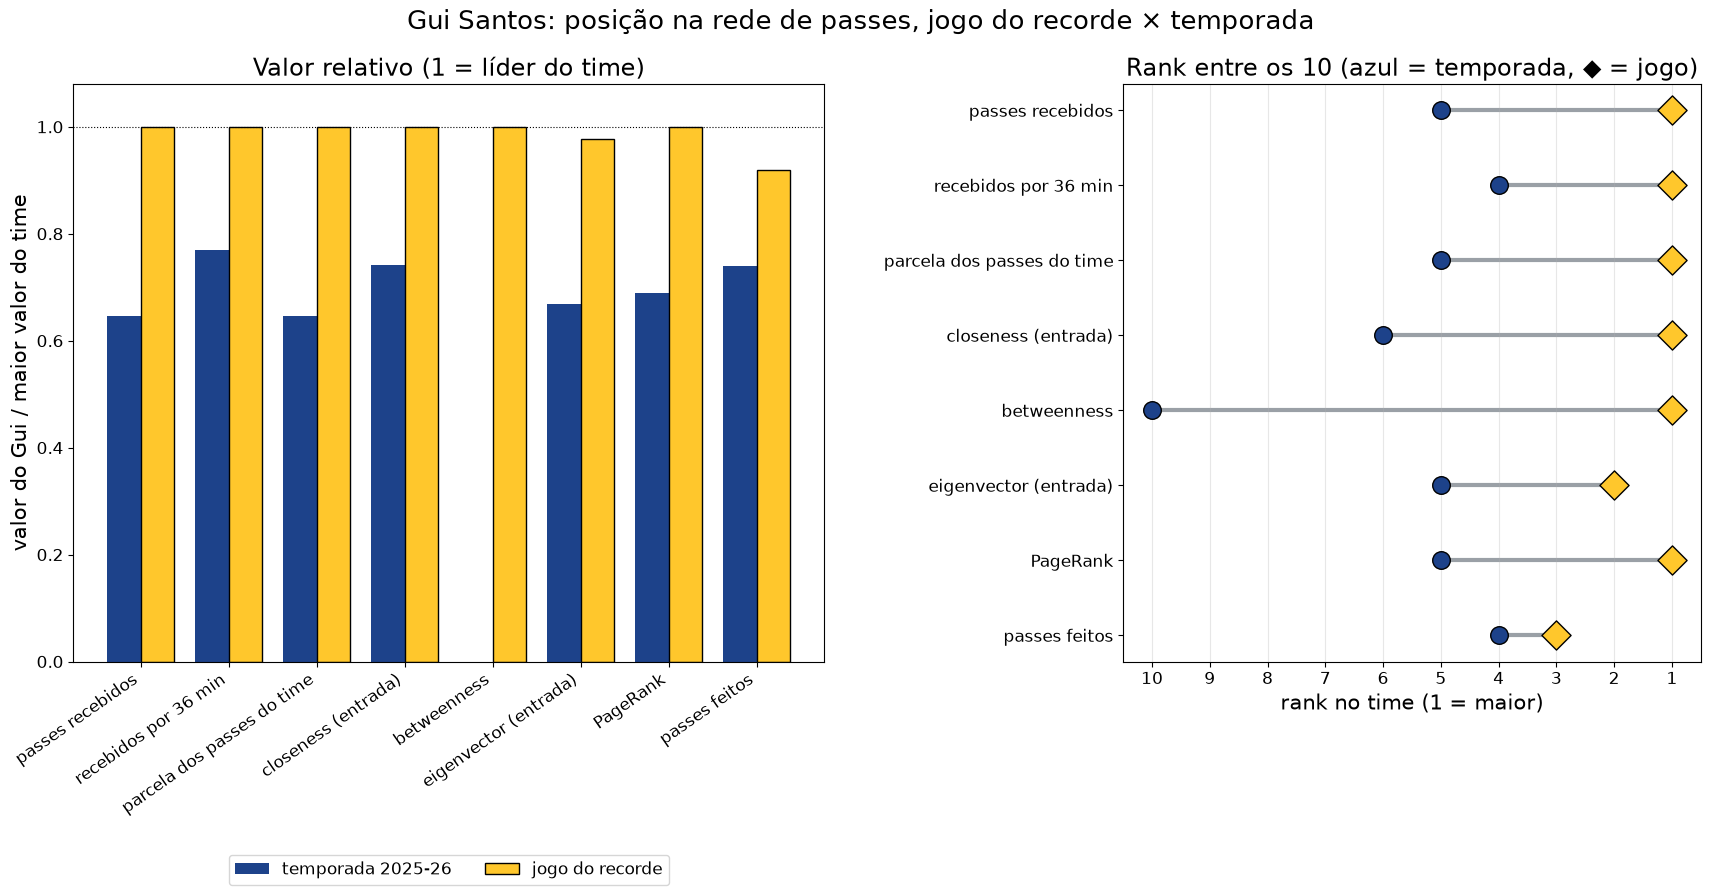

In [20]:
# Figura: centralidades do Gui (valor relativo ao máximo do time), jogo x temporada
fig, axes = plt.subplots(1, 2, figsize=(21, 7.5), gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.45})
x = np.arange(len(comp)); w = 0.38
ax = axes[0]
ax.bar(x - w/2, comp["valor_temp / máx"], w, color=AZUL, label="temporada 2025-26")
ax.bar(x + w/2, comp["valor_jogo / máx"], w, color=OURO, edgecolor="black", label="jogo do recorde")
ax.set_xticks(x, comp.index, rotation=35, ha="right"); ax.set_ylim(0, 1.08)
ax.axhline(1, color="black", lw=0.8, ls=":")
ax.set_ylabel("valor do Gui / maior valor do time"); ax.set_title("Valor relativo (1 = líder do time)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2)
ax = axes[1]
for i, (med, row) in enumerate(comp.iterrows()):
    ax.plot([row["rank_temporada"], row["rank_jogo"]], [i, i], color=CINZA, lw=3, zorder=1)
    ax.scatter(row["rank_temporada"], i, color=AZUL, s=160, zorder=2, edgecolor="black")
    ax.scatter(row["rank_jogo"], i, color=OURO, s=220, zorder=3, edgecolor="black", marker="D")
ax.set_yticks(range(len(comp)), comp.index); ax.invert_yaxis()
ax.set_xticks(range(1, 11)); ax.set_xlim(10.5, 0.5)
ax.set_xlabel("rank no time (1 = maior)"); ax.set_title("Rank entre os 10 (azul = temporada, ◆ = jogo)")
ax.grid(axis="x", alpha=0.3)
fig.suptitle("Gui Santos: posição na rede de passes, jogo do recorde × temporada", fontsize=19)
plt.savefig(FIG / "03_centralidades_gui_jogo_vs_temporada.png"); plt.show()

In [21]:
# Conceito: atributos das arestas (FGA e AST associados ao passe): de onde vieram os pontos — Semana 2
# rec_*: passes RECEBIDOS por cada jogador, de QUALQUER passador (inclusive quem está fora da rede).
# Para cada passe, o rastreamento informa se o recebedor arremessou na sequência (FGA, com ou sem
# drible) e se o passe virou assistência (AST). Arremessos SEM passe antes = rebote ofensivo,
# roubo/contra-ataque individual. Cesta ASSISTIDA = criada pelo passe de um companheiro.
def origem_arremessos(rec, totais):
    s = rec.groupby("recebedor_id")[["passes", "fga", "assistencias"]].sum()
    s = s.join(totais[["fga", "fgm"]].rename(columns={"fga": "fga_total", "fgm": "fgm_total"}))
    s["% FGA precedidos de passe"] = 100 * s["fga"] / s["fga_total"]
    s["% cestas assistidas"] = 100 * s["assistencias"] / s["fgm_total"]
    s.index = s.index.map(rot)
    return s

oa_j = origem_arremessos(rec_j, jj.set_index("player_id"))
oa_t = origem_arremessos(rec_t, jt.set_index("player_id"))
tab_oa = pd.DataFrame({"cestas (jogo)": oa_j["fgm_total"], "assistidas (jogo)": oa_j["assistencias"],
                       "% assistidas · jogo": oa_j["% cestas assistidas"],
                       "% assistidas · temporada": oa_t["% cestas assistidas"],
                       "% FGA após passe · jogo": oa_j["% FGA precedidos de passe"],
                       "% FGA após passe · temporada": oa_t["% FGA precedidos de passe"]}
                      ).sort_values("cestas (jogo)", ascending=False)
display(tab_oa)
g = tab_oa.loc["Gui Santos"]
print(f"Gui: {g['assistidas (jogo)']:.0f} das {g['cestas (jogo)']:.0f} cestas foram assistidas "
      f"({g['% assistidas · jogo']:.0f}%; temporada: {g['% assistidas · temporada']:.0f}%). "
      f"{g['% FGA após passe · jogo']:.0f}% dos arremessos vieram depois de receber um passe "
      f"(temporada: {g['% FGA após passe · temporada']:.0f}%).")

,cestas (jogo),assistidas (jogo),% assistidas · jogo,% assistidas · temporada,% FGA após passe · jogo,% FGA após passe · temporada
recebedor_id,,,,,,
Gui Santos,11,6.0,54.545,76.957,100.000,91.739
Podziemski,6,3.0,50.000,65.482,81.818,92.379
Payton II,5,5.0,100.000,82.645,100.000,87.952
Melton,5,1.0,20.000,57.209,91.667,90.341
Porziņģis,4,2.0,50.000,63.636,88.889,91.011
Green,2,2.0,100.000,91.220,100.000,96.130
Spencer,2,1.0,50.000,43.011,100.000,92.431
Richard,1,1.0,100.000,80.864,100.000,87.572
Yurtseven,0,0.0,NaN,54.545,100.000,65.385


Gui: 6 das 11 cestas foram assistidas (55%; temporada: 77%). 100% dos arremessos vieram depois de receber um passe (temporada: 92%).


Amostra: 20 jogos do Gui com >= 10 min, de 02/28/2026 a 04/12/2026 (sem Curry e sem Butler em quadra: 17; o recorde é um deles: True)
medida               recorde   mediana  percentil  mediana*  percentil*
passes_recebidos      61.000    43.500       97.5    44.000        97.1
recebidos_36          62.743    51.112       97.5    51.600        97.1
parcela_recebida       0.192     0.127       97.5     0.131        97.1
pontos                31.000    15.000       97.5    16.000        97.1
* = só entre os jogos sem Curry e sem Butler (mesmo contexto de desfalques do recorde)

Correlação de Spearman com os pontos (entre jogos):
pontos              1.00
passes_recebidos    0.75
recebidos_36        0.63
parcela_recebida    0.69


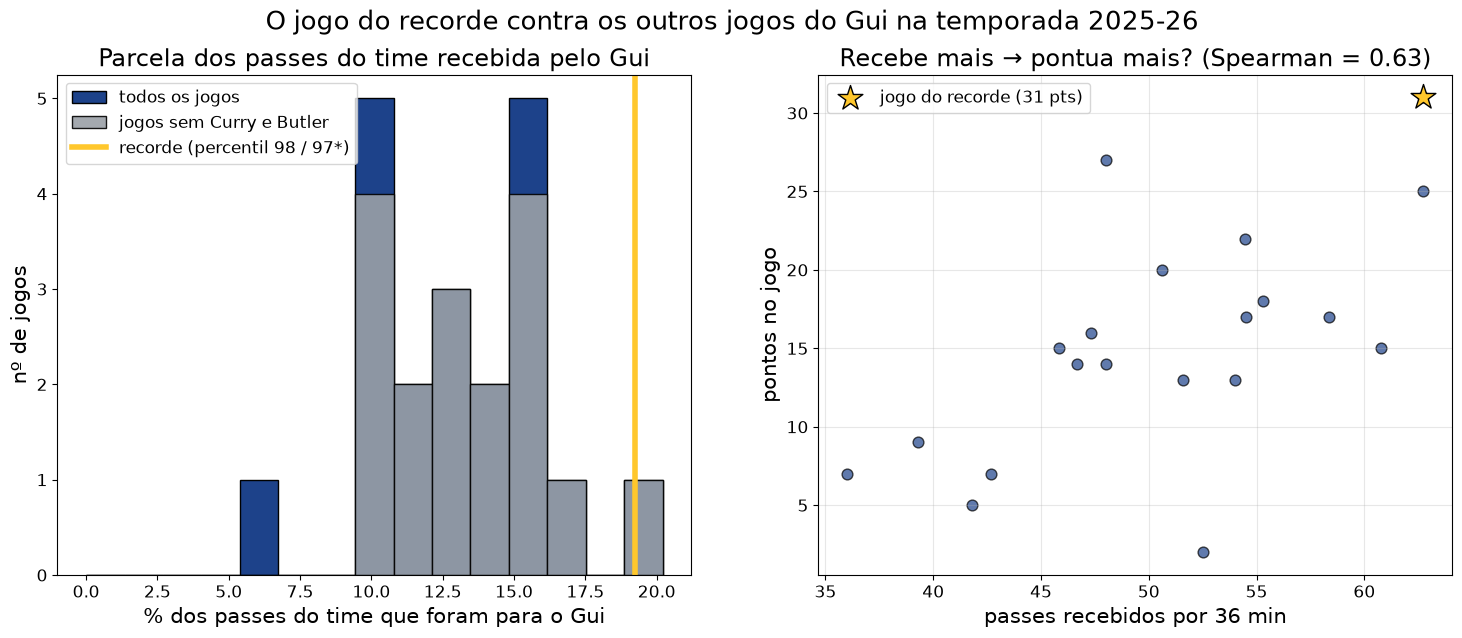

In [22]:
# Melhoria: o jogo do recorde contra a DISTRIBUIÇÃO de outros jogos do Gui na temporada
# AMOSTRA PARCIAL: a coleta jogo a jogo foi limitada pela taxa de requests do stats.nba.com;
# usamos os jogos já baixados (os mais recentes da temporada). Com BAIXAR_DADOS = True e tempo,
# coleta.coletar_tudo() completa os 68 jogos.
gpj = pd.read_csv(PROC / "gui_por_jogo.csv")
gpj = gpj[gpj["minutos"] >= 10].copy()          # jogos com >= 10 minutos (evita ruído de garbage time)
gpj["recebidos_36"] = gpj["passes_recebidos"] / gpj["minutos"] * 36
gpj["parcela_recebida"] = gpj["passes_recebidos"] / gpj["passes_time"]
gpj["recorde"] = gpj["game_id"].astype(str).str.zfill(10) == str(jogo["game_id"]).zfill(10)
rec_row = gpj[gpj["recorde"]].iloc[0]

def percentil(serie, valor):
    return 100 * (serie < valor).mean() + 50 * (serie == valor).mean()

estrelas = pd.read_csv(PROC / "estrelas_jogos.csv", dtype={"game_id": str})
com_estrela = set(estrelas["game_id"].str.zfill(10))
gpj["sem_curry_butler"] = ~gpj["game_id"].astype(str).str.zfill(10).isin(com_estrela)
rec_row = gpj[gpj["recorde"]].iloc[0]

metricas = ["passes_recebidos", "recebidos_36", "parcela_recebida", "pontos"]
pct = {c: percentil(gpj[c], rec_row[c]) for c in metricas}
sem = gpj[gpj["sem_curry_butler"]]
pct_sem = {c: percentil(sem[c], rec_row[c]) for c in metricas}
print(f"Amostra: {len(gpj)} jogos do Gui com >= 10 min, de {gpj.data.min()} a {gpj.data.max()} "
      f"(sem Curry e sem Butler em quadra: {len(sem)}; o recorde é um deles: {bool(rec_row['sem_curry_butler'])})")
print(f"{'medida':18s} {'recorde':>9s} {'mediana':>9s} {'percentil':>10s} {'mediana*':>9s} {'percentil*':>11s}")
for c in metricas:
    print(f"{c:18s} {rec_row[c]:9.3f} {gpj[c].median():9.3f} {pct[c]:10.1f} "
          f"{sem[c].median():9.3f} {pct_sem[c]:11.1f}")
print("* = só entre os jogos sem Curry e sem Butler (mesmo contexto de desfalques do recorde)")
corr = gpj[["pontos", "passes_recebidos", "recebidos_36", "parcela_recebida"]].corr(method="spearman")["pontos"]
print("\nCorrelação de Spearman com os pontos (entre jogos):"); print(corr.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
ax = axes[0]
bins = np.linspace(0, gpj["parcela_recebida"].max() * 100 * 1.05, 16)
ax.hist(gpj["parcela_recebida"] * 100, bins=bins, color=AZUL, edgecolor="black", label="todos os jogos")
ax.hist(sem["parcela_recebida"] * 100, bins=bins, color=CINZA, edgecolor="black", alpha=0.9,
        label="jogos sem Curry e Butler")
ax.axvline(rec_row["parcela_recebida"] * 100, color=OURO, lw=4,
           label=f"recorde (percentil {pct['parcela_recebida']:.0f} / {pct_sem['parcela_recebida']:.0f}*)")
ax.set_xlabel("% dos passes do time que foram para o Gui"); ax.set_ylabel("nº de jogos")
ax.set_title("Parcela dos passes do time recebida pelo Gui"); ax.legend()
ax = axes[1]
ax.scatter(gpj["recebidos_36"], gpj["pontos"], color=AZUL, s=60, alpha=0.7, edgecolor="black")
ax.scatter(rec_row["recebidos_36"], rec_row["pontos"], color=OURO, s=350, marker="*",
           edgecolor="black", zorder=3, label="jogo do recorde (31 pts)")
ax.set_xlabel("passes recebidos por 36 min"); ax.set_ylabel("pontos no jogo")
ax.set_title(f"Recebe mais → pontua mais? (Spearman = {corr['recebidos_36']:.2f})"); ax.legend()
ax.grid(alpha=0.3)
fig.suptitle("O jogo do recorde contra os outros jogos do Gui na temporada 2025-26", fontsize=19)
plt.savefig(FIG / "08_percentil_temporada.png"); plt.show()

## 8. Alternativas de modelagem e sensibilidade ao limiar

In [23]:
# Conceito: esqueleto por limiar (remover arestas com < k passes) — Semana 6
ks = [1, 2, 3, 5]
linhas = []
for k in ks:
    for nome, G in [("jogo", Gj), ("temporada", Gt)]:
        H = r.esqueleto(G, k)
        m = r.medidas_nos(H)
        rk = r.ranks(m, ["forca_entrada", "betweenness", "eigenvector_entrada", "closeness_entrada"])
        linhas.append({"k": k, "rede": nome, "arestas": H.number_of_edges(),
                       "densidade": nx.density(H), "n_scc": nx.number_strongly_connected_components(H),
                       "rank_recebidos": rk.loc["Gui Santos", "forca_entrada"],
                       "rank_betweenness": rk.loc["Gui Santos", "betweenness"],
                       "rank_eigenvector": rk.loc["Gui Santos", "eigenvector_entrada"],
                       "rank_closeness": rk.loc["Gui Santos", "closeness_entrada"],
                       "betweenness_gui": m.loc["Gui Santos", "betweenness"],
                       "core_gui": m.loc["Gui Santos", "core_number"]})
sens = pd.DataFrame(linhas)
sens.to_csv(PROC / "sensibilidade_limiar.csv", index=False)
sens

,k,rede,arestas,densidade,n_scc,rank_recebidos,rank_betweenness,rank_eigenvector,rank_closeness,betweenness_gui,core_gui
0,1,jogo,68,0.756,1,1,1,2,1,0.326,6
1,1,temporada,72,0.800,1,5,10,5,6,0.000,7
2,2,jogo,55,0.611,1,1,1,2,1,0.326,5
3,2,temporada,52,0.578,1,6,10,5,6,0.000,5
4,3,jogo,45,0.500,1,1,1,2,1,0.326,4
5,3,temporada,40,0.444,3,7,10,6,7,0.000,5
6,5,jogo,29,0.322,3,1,1,2,1,0.347,4
7,5,temporada,13,0.144,5,7,10,5,5,0.000,1


In [24]:
# Conceito: similaridade de Jaccard entre conjuntos de arestas (jogo x temporada) — Semana 6
# Quanto do "esqueleto" do jogo é o mesmo esqueleto da temporada? E as ligações do Gui?
for k in ks:
    Ej, Et = set(r.esqueleto(Gj, k).edges()), set(r.esqueleto(Gt, k).edges())
    Ej_g = {e for e in Ej if GUI in e}; Et_g = {e for e in Et if GUI in e}
    jac = len(Ej & Et) / len(Ej | Et) if Ej | Et else np.nan
    jac_g = len(Ej_g & Et_g) / len(Ej_g | Et_g) if Ej_g | Et_g else np.nan
    print(f"k = {k}: Jaccard(rede inteira) = {jac:.2f} · Jaccard(arestas do Gui) = {jac_g:.2f} "
          f"· arestas do Gui no jogo = {len(Ej_g)}, na temporada = {len(Et_g)}")

k = 1: Jaccard(rede inteira) = 0.82 · Jaccard(arestas do Gui) = 1.00 · arestas do Gui no jogo = 18, na temporada = 18
k = 2: Jaccard(rede inteira) = 0.67 · Jaccard(arestas do Gui) = 0.76 · arestas do Gui no jogo = 17, na temporada = 13
k = 3: Jaccard(rede inteira) = 0.57 · Jaccard(arestas do Gui) = 0.53 · arestas do Gui no jogo = 16, na temporada = 10
k = 5: Jaccard(rede inteira) = 0.40 · Jaccard(arestas do Gui) = 0.17 · arestas do Gui no jogo = 12, na temporada = 2


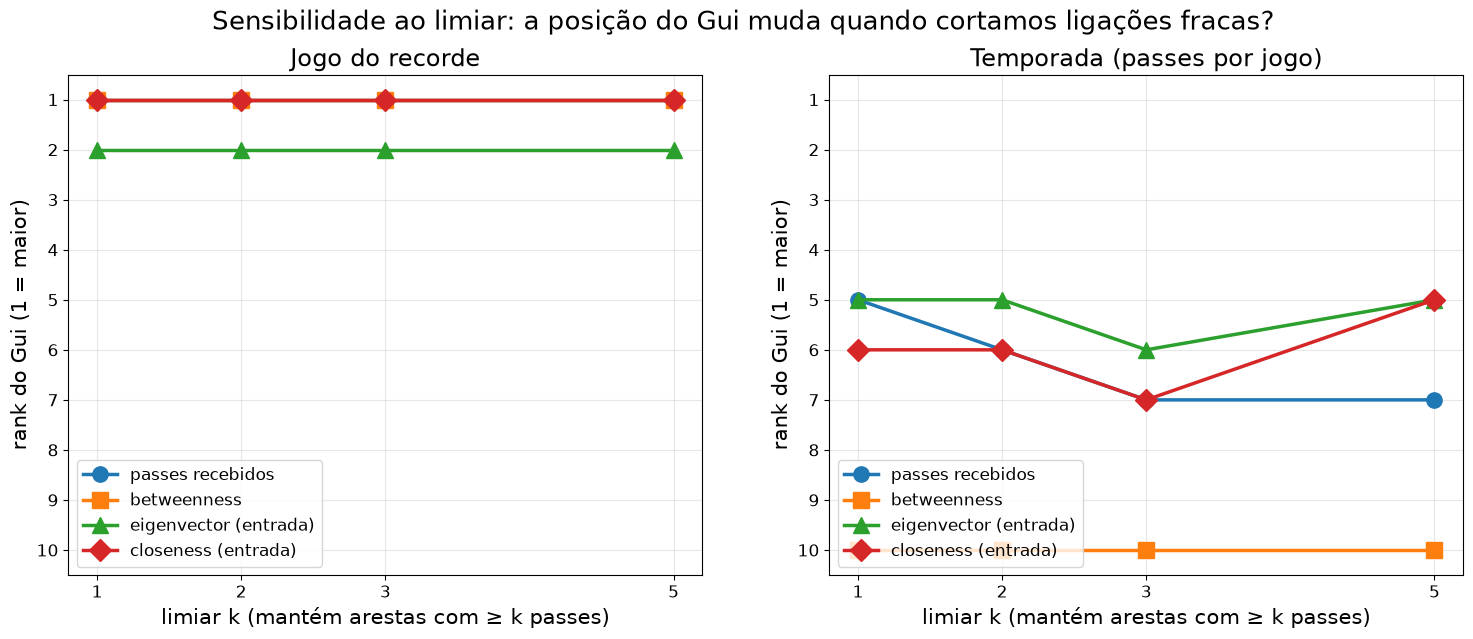

In [25]:
# Figura: sensibilidade ao limiar
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
estilos = {"rank_recebidos": ("passes recebidos", "o"), "rank_betweenness": ("betweenness", "s"),
           "rank_eigenvector": ("eigenvector (entrada)", "^"), "rank_closeness": ("closeness (entrada)", "D")}
for ax, nome in zip(axes, ["jogo", "temporada"]):
    s = sens[sens["rede"] == nome]
    for col, (rot_m, mk) in estilos.items():
        ax.plot(s["k"], s[col], marker=mk, ms=11, lw=2.5, label=rot_m)
    ax.set_xticks(ks); ax.set_yticks(range(1, 11)); ax.set_ylim(10.5, 0.5)
    ax.set_xlabel("limiar k (mantém arestas com ≥ k passes)"); ax.set_ylabel("rank do Gui (1 = maior)")
    ax.set_title("Jogo do recorde" if nome == "jogo" else "Temporada (passes por jogo)")
    ax.grid(alpha=0.3); ax.legend(loc="lower left")
fig.suptitle("Sensibilidade ao limiar: a posição do Gui muda quando cortamos ligações fracas?", fontsize=19)
plt.savefig(FIG / "04_sensibilidade_limiar.png"); plt.show()

In [26]:
# Conceito: modelagens alternativas (peso = assistências; rede não dirigida) — Semanas 2 e 4
Gj_ast = r.montar_rede(aj, jj, coluna_peso="assistencias")
print(f"Rede de ASSISTÊNCIAS do jogo: {Gj_ast.number_of_edges()} arestas, "
      f"{Gj_ast.size(weight='peso'):.0f} assistências")
print("Assistências recebidas por jogador (quem foi assistido):")
print(pd.Series(dict(Gj_ast.in_degree(weight="peso"))).rename(rot).sort_values(ascending=False).to_string())

# não dirigida: perde a diferença entre passar e receber
btw_u = nx.betweenness_centrality(Uj, weight="distancia")
eig_u = nx.eigenvector_centrality(Uj, weight="peso", max_iter=5000)
alt = pd.DataFrame({"betweenness_dirigida": mj["betweenness"],
                    "betweenness_nao_dirigida": pd.Series(btw_u).rename(rot),
                    "eigenvector_entrada": mj["eigenvector_entrada"],
                    "eigenvector_nao_dirigida": pd.Series(eig_u).rename(rot)})
alt.sort_values("betweenness_dirigida", ascending=False)

Rede de ASSISTÊNCIAS do jogo: 17 arestas, 21 assistências
Assistências recebidas por jogador (quem foi assistido):
Gui Santos    6.0
Payton II     5.0
Podziemski    3.0
Green         2.0
Porziņģis     2.0
Melton        1.0
Richard       1.0
Spencer       1.0
Yurtseven     0.0
Cryer         0.0


,betweenness_dirigida,betweenness_nao_dirigida,eigenvector_entrada,eigenvector_nao_dirigida
Gui Santos,0.326,0.278,0.480,0.423
Podziemski,0.312,0.306,0.491,0.480
Melton,0.208,0.222,0.376,0.391
Green,0.097,0.000,0.411,0.441
Spencer,0.014,0.000,0.161,0.161
Porziņģis,0.000,0.000,0.336,0.321
Payton II,0.000,0.000,0.153,0.214
Cryer,0.000,0.000,0.182,0.183
Yurtseven,0.000,0.000,0.102,0.119
Richard,0.000,0.000,0.115,0.144


## Conclusão

O texto abaixo resume o que os números das células anteriores mostram; o README traz a mesma síntese.

**O time jogou para ele.** No jogo do recorde, a bola fluiu pelo Gui mais do que por qualquer companheiro. Ele foi o 1º do time em passes recebidos (61, ou 19% de todos os passes do GSW, e continua 1º por 36 minutos), em betweenness, closeness de entrada e PageRank, e o 2º em eigenvector. Na temporada, ele fica entre o 4º e o 6º nessas mesmas medidas, com betweenness zero. Comparado com os outros 20 jogos dele que coletamos, foi o jogo em que ele mais recebeu a bola (percentil 98), inclusive entre os jogos sem Curry e Butler. **A ressalva:** a estrutura levou a bola até ele, mas ele converteu com mais criação própria do que o normal: 55% das cestas foram assistidas, contra 77% na temporada. E o contexto ajudou, porque Curry e Butler estavam fora. Para o scouting, o efeito é **estrutural, mas condicionado aos desfalques**.

**Leitura dos resultados, seção por seção do notebook:**

- **Descrição (sem. 2):** 10 nós, 68 arestas e 317 passes no jogo; densidade 0,76 e reciprocidade 0,91. Como quase todos passam para quase todos, o **grau sem peso não discrimina** (o Gui recebeu de todos os 9 companheiros, assim como Payton II). O que discrimina é o peso. No heatmap, a coluna do Gui é a mais carregada: Green → Gui (13), Podziemski → Gui (11), Yurtseven → Gui (10).
- **Entrada e saída (sem. 3):** o Gui recebeu 61 passes e fez 45. Ele foi mais **destino** do que distribuidor, ao contrário de Green e Payton II, que passam mais do que recebem. O confundidor "minutos" não explica isso: por 36 min ele continua em 1º (62,9 contra 58,8 de Melton e 58,4 de Podziemski). Seis companheiros passaram para ele 5 vezes ou mais (BFS/snowball no esqueleto ≥5).
- **Componentes e caminhos (sem. 4):** uma única SCC, diâmetro 2, distância média de 1,24 salto. A distância ponderada média **até** o Gui (0,163) é a menor do time, ou seja, a bola chegava a ele por caminhos "curtos" (com muitos passes).
- **Centralidades (sem. 4):** na temporada, a betweenness se concentra em Podziemski, Spencer e Green, e o Gui tem zero. No jogo, ele passa a ser a principal ponte (0,326), à frente de Podziemski (0,312).
- **Núcleos (sem. 5):** sem limiar, todos estão no 6-core (a rede é densa demais para separar alguém). No **esqueleto por limiar**, o Gui permanece no núcleo mais coeso até com ≥8 passes por par (4-core), junto com Green, Podziemski, Melton e Porziņģis. O maior **k-truss** com ligações ≥5 é um 5-truss formado exatamente por esses 5 jogadores.
- **Robustez:** remover o Gui derruba a eficiência ponderada em 15,6% e leva 33% dos passes junto, **o mesmo efeito de remover Podziemski**, o organizador do time. Remover qualquer outro jogador praticamente não muda a eficiência (−1,8% em média). Na rede da temporada, remover o Gui custa só 0,5%. Naquela noite, o ataque dependia dele.
- **Distribuição (melhoria):** em 20 jogos do Gui (28/02 a 12/04/2026), o recorde é o **maior** em passes recebidos, recebidos por 36 min e parcela do time (19,2% contra mediana de 12,7%). Isso continua valendo entre os 17 jogos sem Curry e Butler. Entre jogos, receber mais está associado a pontuar mais (Spearman de 0,63 com passes recebidos por 36 min; 0,75 com passes recebidos).
- **Sensibilidade ao limiar (sem. 6):** com k = 1, 2, 3 e 5, o Gui continua em 1º em passes recebidos, betweenness e closeness, e em 2º em eigenvector, na rede do jogo. Na temporada, fica entre o 5º e o 7º. **A conclusão não depende do limiar.** Jaccard: com k = 5, só 17% das ligações fortes do Gui no jogo também são ligações fortes na temporada (12 no jogo contra 2 na temporada), então foi uma estrutura nova em volta dele.
- **Modelagens alternativas:** com peso = assistências, o Gui foi o jogador mais assistido (6 de 21 assistências do time). Na versão **não dirigida**, a betweenness dele cai para 0,278 e Podziemski passa à frente (0,306). Ignorar a direção esconde justamente o papel de **receptor**, o que justifica o modelo dirigido.
- **Nuance importante (atributos das arestas):** todos os 16 arremessos do Gui vieram depois de receber um passe (nenhum de rebote ofensivo ou roubo), mas só 6 das 11 cestas foram assistidas. Ou seja, ele recebia e muitas vezes criava a partir daí (drible, isolação). O time escolheu **dar a bola** a ele; a finalização teve mais mérito individual do que o normal.